# 06 · Robustez del modelo y homicidio a escala provincial

Dos comprobaciones adicionales sobre el modelo del notebook 04:

1. **¿El resultado se mantiene en otros periodos?** En el notebook 04 el modelo se evaluó en un solo periodo de prueba. Aquí se repite la evaluación en cinco cortes temporales distintos (*validación con origen móvil*).
2. **¿A qué escala tiene sentido pronosticar el homicidio?** Por cantón y mes el azar domina; se mide el error al agregar por provincia y para todo el país.

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

from src import modelo, viz

viz.estilo()
FIG = RAIZ / 'reports' / 'figures'
P = lambda s: pd.Period(s, 'M')
CONFIG = json.loads((RAIZ / 'models' / 'lgbm_config.json').read_text())
wape = lambda y, p: np.abs(p - y).sum() / y.sum()

## 1. Validación con origen móvil

Para cada corte, el modelo se entrena **solo con datos anteriores** y se evalúa en el periodo siguiente, con la misma configuración elegida en el notebook 04 (sin volver a ajustarla, para no favorecerlo). Los años 2020 y 2021 no se usan como periodo de prueba porque la pandemia fue un shock que ningún modelo basado en el pasado podía anticipar.

| Corte | Entrenamiento | Prueba |
|---|---|---|
| 2019 | 2015–2018 | 2019 |
| 2022 | 2015–2021 | 2022 |
| 2023 | 2015–2022 | 2023 |
| 2024 | 2015–2023 | 2024 |
| 2025–26 | 2015–2024 | ene 2025 – sep 2026 |

In [2]:
panel = modelo.construir_panel(RAIZ)
CORTES = {'2019': ('2018-12', '2019-01', '2019-12'), '2022': ('2021-12', '2022-01', '2022-12'),
          '2023': ('2022-12', '2023-01', '2023-12'), '2024': ('2023-12', '2024-01', '2024-12'),
          '2025–26': ('2024-12', '2025-01', '2026-09')}

def entrenar(tr):
    m = lgb.LGBMRegressor(objective='poisson', n_estimators=int(CONFIG['arboles']), learning_rate=0.03,
                          num_leaves=int(CONFIG['num_leaves']), min_child_samples=int(CONFIG['min_child_samples']),
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=0)
    m.fit(tr[modelo.VARIABLES], tr['Delitos'], init_score=modelo.offset(tr))
    return m.booster_

partes = []
for corte, (fin, ini, fev) in CORTES.items():
    X = modelo.construir_variables(panel, RAIZ, P(fin)).dropna(subset=['lag_12', 'media_12'])
    tr, te = X[X['Mes'] <= P(fin)], X[X['Mes'].between(P(ini), P(fev))].copy()
    te['LightGBM'] = modelo.predecir(entrenar(tr), te)
    te['Media 12'], te['Media 3'], te['Corte'] = te['media_12'], te['media_3'], corte
    partes.append(te)
bt = pd.concat(partes, ignore_index=True)
print(f'{len(bt):,} pronósticos evaluados en {bt.Mes.nunique()} meses')

33,534 pronósticos evaluados en 69 meses


### 1.1 Precisión en volumen

In [3]:
vol = bt.groupby('Corte', sort=False).apply(lambda g: pd.Series({m: wape(g['Delitos'], g[m]) for m in ['Media 3', 'Media 12', 'LightGBM']}))
vol['Mejora frente a Media 12'] = 1 - vol['LightGBM'] / vol['Media 12']
vol.round(3)

,Media 3,Media 12,LightGBM,Mejora frente a Media 12
Corte,,,,
2019,0.290,0.282,0.284,-0.009
2022,0.333,0.324,0.307,0.051
2023,0.333,0.310,0.310,0.002
2024,0.341,0.329,0.320,0.030
2025–26,0.375,0.364,0.345,0.051


Para saber si las diferencias son reales o fruto del azar se usa un **bootstrap por meses**: se remuestrean los meses de cada periodo 1.000 veces y se calcula el intervalo de confianza del 95 % de la diferencia de error entre el LightGBM y la media de 12 meses. Si el intervalo no incluye el cero, la diferencia es significativa.

In [4]:
rng = np.random.default_rng(0)
filas = []
for corte, g in bt.groupby('Corte', sort=False):
    por_mes = {m: gg for m, gg in g.groupby('Mes')}
    meses = list(por_mes)
    difs = []
    for _ in range(1000):
        s = pd.concat([por_mes[m] for m in rng.choice(meses, len(meses))])
        difs.append(wape(s['Delitos'], s['LightGBM']) - wape(s['Delitos'], s['Media 12']))
    lo, hi = np.percentile(difs, [2.5, 97.5])
    d = wape(g['Delitos'], g['LightGBM']) - wape(g['Delitos'], g['Media 12'])
    filas.append({'Corte': corte, 'Diferencia de WAPE': d, 'IC 95 % inferior': lo, 'IC 95 % superior': hi,
                  'Conclusión': 'LightGBM mejor' if hi < 0 else ('Media 12 mejor' if lo > 0 else 'Sin diferencia significativa')})
ic = pd.DataFrame(filas).set_index('Corte')
ic.round(4)

,Diferencia de WAPE,IC 95 % inferior,IC 95 % superior,Conclusión
Corte,,,,
2019,0.0026,-0.0046,0.0108,Sin diferencia significativa
2022,-0.0164,-0.0211,-0.0109,LightGBM mejor
2023,-0.0006,-0.0073,0.0070,Sin diferencia significativa
2024,-0.0098,-0.0159,-0.0040,LightGBM mejor
2025–26,-0.0187,-0.0242,-0.0131,LightGBM mejor


### 1.2 Detección de aumentos atípicos

In [5]:
umbral = np.maximum(bt['media_12'] * 1.3, bt['media_12'] + 2 * np.sqrt(bt['media_12'] + 1))
bt['Aumento'] = ((bt['Delitos'] > umbral) & (bt['Delitos'] >= 5)).astype(int)

def aciertos_top(g, col, k=10):
    return np.mean([h.loc[(h[col] / (h['media_12'] + 0.5)).nlargest(k).index, 'Aumento'].mean()
                    for _, h in g[g['media_12'] >= 3].groupby('Mes')])

filas = []
for corte, g in bt.groupby('Corte', sort=False):
    for nombre, col in [('Tendencia reciente', 'Media 3'), ('LightGBM', 'LightGBM')]:
        r = g[col] / (g['media_12'] + 0.5)
        filas.append({'Corte': corte, 'Criterio': nombre, 'Aciertos top 10': aciertos_top(g, col),
                      'AP': average_precision_score(g['Aumento'], r), 'AUC': roc_auc_score(g['Aumento'], r)})
alertas = pd.DataFrame(filas).pivot(index='Corte', columns='Criterio').reindex(list(CORTES))
alertas['Azar', ''] = bt.groupby('Corte')['Aumento'].mean().reindex(list(CORTES))
alertas.round(3)

Aciertos top 10                          AP                     \
Criterio        LightGBM Tendencia reciente LightGBM Tendencia reciente   
Corte                                                                     
2019               0.108              0.108    0.086              0.074   
2022               0.233              0.133    0.155              0.113   
2023               0.150              0.067    0.101              0.067   
2024               0.158              0.083    0.103              0.059   
2025–26            0.152              0.081    0.117              0.064   

              AUC                      Azar  
Criterio LightGBM Tendencia reciente         
Corte                                        
2019        0.702              0.652  0.047  
2022        0.737              0.677  0.073  
2023        0.691              0.640  0.049  
2024        0.692              0.630  0.040  
2025–26     0.712              0.641  0.043

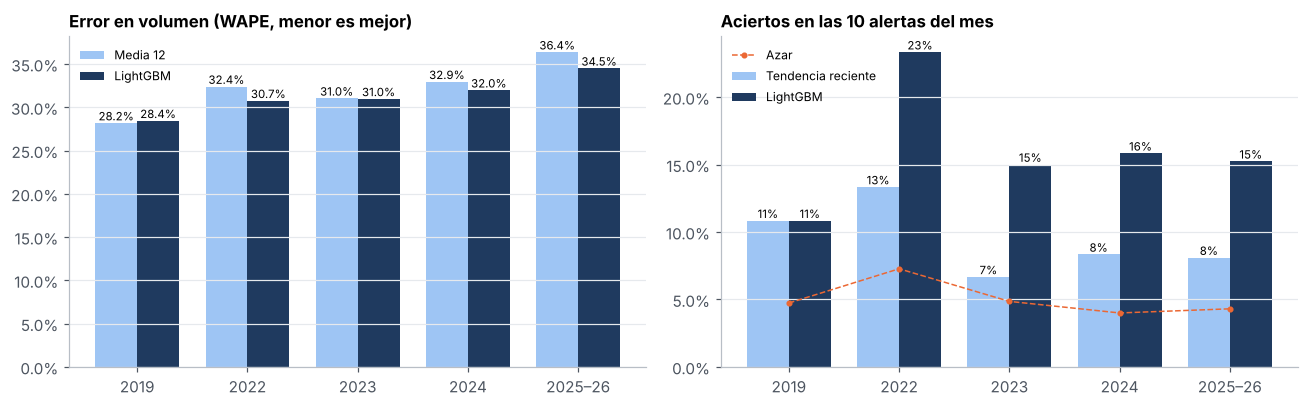

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(CORTES))
for ax, (tabla, cols, titulo, fmt) in zip(axes, [
        (vol, ['Media 12', 'LightGBM'], 'Error en volumen (WAPE, menor es mejor)', '{:.1%}'),
        (alertas['Aciertos top 10'], ['Tendencia reciente', 'LightGBM'], 'Aciertos en las 10 alertas del mes', '{:.0%}')]):
    for i, (c, color) in enumerate(zip(cols, ['#9ec5f4', viz.AZUL])):
        v = tabla[c].values
        ax.bar(x + (i - 0.5) * 0.38, v, width=0.38, color=color, label=c)
        for xi, vi in zip(x, v):
            ax.text(xi + (i - 0.5) * 0.38, vi, fmt.format(vi), ha='center', va='bottom', fontsize=7.5)
    ax.set_xticks(x, list(CORTES)); ax.set_title(titulo); ax.legend(loc='upper left', fontsize=8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.grid(axis='x', visible=False)
axes[1].plot(x, alertas['Azar'].values, color=viz.NARANJA, ls='--', marker='o', ms=3, lw=1, label='Azar')
axes[1].legend(loc='upper left', fontsize=8)
fig.tight_layout()
fig.savefig(FIG / '06_robustez_cortes.png')

**Lectura:**

- **En volumen, el modelo nunca es significativamente peor que la media de 12 meses**, pero su ventaja es pequeña y varía según el periodo: es significativa en 2022, 2024 y 2025–26, y no lo es en 2019 y 2023 (los intervalos de confianza incluyen el cero). Es una conclusión honesta: para predecir *cuántos* delitos habrá, la historia reciente ya explica casi todo.
- **En la detección de aumentos, la ventaja es consistente:** el LightGBM supera a la tendencia reciente en AUC y en precisión media (AP) en los cinco periodos, y en aciertos de las 10 alertas mensuales gana en cuatro y empata en 2019. Su precisión ronda el 15 %, aproximadamente el doble que el criterio simple y tres veces el azar.
- **La conclusión del notebook 04 se sostiene:** el valor del modelo no es acertar mejor el volumen, sino anticipar dónde va a subir el delito.

## 2. Homicidio: ¿a qué escala pronosticarlo?

Un cantón típico registra menos de un homicidio al mes, así que el número observado depende mucho del azar. Se suman los pronósticos y los valores reales por provincia y para todo el país, y se mide el error a cada escala. Son pronósticos a un mes vista en todos los casos.

In [7]:
hom = bt[bt['Delito'] == 'HOMICIDIO']
filas = []
for nivel, claves in [('Cantón', ['Canton', 'Mes']), ('Provincia', ['Provincia', 'Mes']), ('País', ['Mes'])]:
    for corte, g in hom.groupby('Corte', sort=False):
        a = g.groupby(claves)[['Delitos', 'LightGBM', 'Media 12']].sum()
        filas.append({'Escala': nivel, 'Corte': corte, 'LightGBM': wape(a['Delitos'], a['LightGBM']),
                      'Media 12': wape(a['Delitos'], a['Media 12']), 'Homicidios por unidad y mes': a['Delitos'].mean()})
esc = pd.DataFrame(filas)
resumen = esc.groupby('Escala', sort=False)[['Homicidios por unidad y mes', 'Media 12', 'LightGBM']].mean()
resumen.round(3)

,Homicidios por unidad y mes,Media 12,LightGBM
Escala,,,
Cantón,0.886,0.802,0.822
Provincia,10.250,0.314,0.314
País,71.752,0.125,0.121


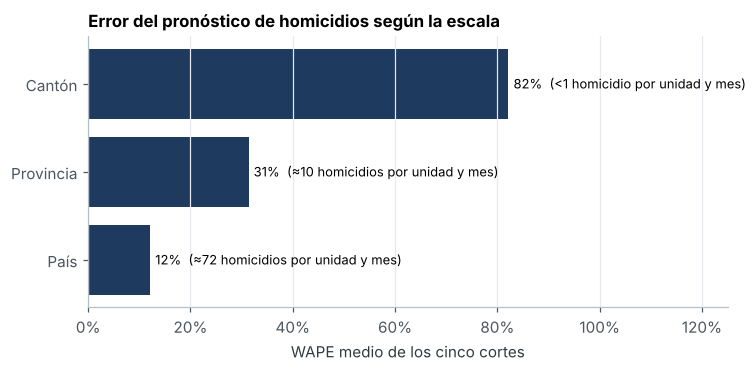

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
v = resumen['LightGBM']
ax.barh(v.index[::-1], v.values[::-1], color=viz.AZUL)
for i, (x_, n) in enumerate(zip(v.values[::-1], resumen['Homicidios por unidad y mes'].values[::-1])):
    ax.text(x_ + 0.01, i, f'{x_:.0%}  (≈{n:.0f} homicidios por unidad y mes)' if n >= 1 else f'{x_:.0%}  (<1 homicidio por unidad y mes)', va='center', fontsize=8.5)
ax.set_xlim(0, 1.25); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.grid(axis='y', visible=False)
ax.set_xlabel('WAPE medio de los cinco cortes'); ax.set_title('Error del pronóstico de homicidios según la escala')
fig.savefig(FIG / '06_homicidio_escala.png')

**Lectura:**

- **Por cantón el error ronda el 80 %:** con menos de un homicidio al mes por cantón, el pronóstico no es informativo.
- **Por provincia baja a alrededor del 30 %**, y **para todo el país a cerca del 12 %**.
- Para el homicidio, el LightGBM y la media de 12 meses rinden casi igual: el homicidio depende de dinámicas (conflictos entre grupos, por ejemplo) que estos datos no recogen.

**Cambio en el sistema:** el homicidio se excluye de las alertas por cantón y se presenta como **pronóstico por provincia** en la aplicación, donde el error es razonable.

## 3. Conclusiones

1. **El modelo es robusto:** en cinco periodos distintos nunca es significativamente peor que la referencia simple, y en la tarea para la que se diseñó, anticipar aumentos, es consistentemente mejor.
2. **Se cuantifica con honestidad dónde aporta y dónde no:** la mejora en volumen es pequeña y no siempre significativa; la mejora en alertas es clara.
3. **El homicidio se pronostica a escala provincial**, que es la escala a la que el resultado es útil.